In [22]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST dataset
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Normalize images to [-1, 1]
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = x_train[..., np.newaxis]

# Create dataset
batch_size = 128

dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(60000).batch(batch_size, drop_remainder=True)

print("Training images:", x_train.shape)

Training images: (60000, 28, 28, 1)


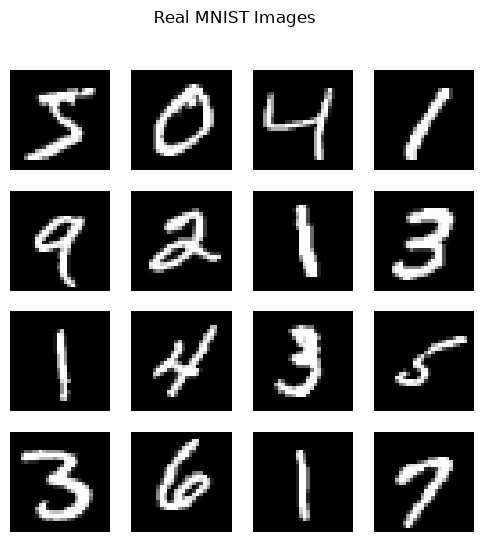

In [23]:
plt.figure(figsize=(6, 6))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(x_train[i, :, :, 0], cmap="gray")
    plt.axis("off")

plt.suptitle("Real MNIST Images")
plt.show()

In [24]:
latent_dim = 100

generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(latent_dim,)),
    tf.keras.layers.Dense(256),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),

    tf.keras.layers.Dense(512),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),

    tf.keras.layers.Dense(1024),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),

    tf.keras.layers.Dense(784, activation="tanh"),
    tf.keras.layers.Reshape((28, 28, 1))
])

generator.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 784)            │       803,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,492,496 (5.69 MB)

 Trainable params: 1,489,424 (5.68 MB)

 Non-trainable params: 3,072 (12.00 KB)

In [25]:
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(1024),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(512),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(256),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

discriminator.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1024)           │       803,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,460,225 (5.57 MB)

 Trainable params: 1,460,225 (5.57 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dense(128),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

discriminator.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 233,985 (914.00 KB)

 Trainable params: 233,985 (914.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30 | D Loss: 0.5873 | G Loss: 1.1313
Epoch 2/30 | D Loss: 0.5699 | G Loss: 1.0589
Epoch 3/30 | D Loss: 0.5366 | G Loss: 1.1893
Epoch 4/30 | D Loss: 0.5429 | G Loss: 1.1775
Epoch 5/30 | D Loss: 0.5469 | G Loss: 1.1639


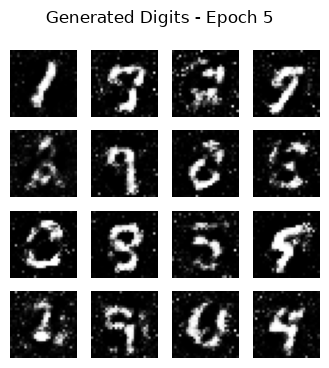

Epoch 6/30 | D Loss: 0.5532 | G Loss: 1.1584
Epoch 7/30 | D Loss: 0.5633 | G Loss: 1.1194
Epoch 8/30 | D Loss: 0.5717 | G Loss: 1.1035
Epoch 9/30 | D Loss: 0.5804 | G Loss: 1.0722
Epoch 10/30 | D Loss: 0.5837 | G Loss: 1.0559


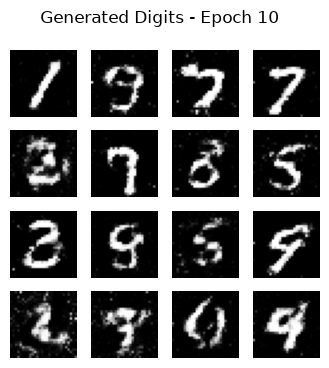

Epoch 11/30 | D Loss: 0.5899 | G Loss: 1.0361


KeyboardInterrupt: 

In [26]:
epochs = 30

g_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
d_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)

loss_fn = tf.keras.losses.BinaryCrossentropy()

g_losses = []
d_losses = []
generated_samples = []

fixed_noise = tf.random.normal((16, latent_dim))

@tf.function
def train_step(real_images):

    n = tf.shape(real_images)[0]

    # Train Discriminator
    noise = tf.random.normal((n, latent_dim))

    with tf.GradientTape() as tape:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(
            tf.stop_gradient(fake_images), training=True
        )

        d_loss = (
            loss_fn(tf.ones_like(real_output), real_output)
            + loss_fn(tf.zeros_like(fake_output), fake_output)
        ) / 2

    d_grads = tape.gradient(
        d_loss, discriminator.trainable_variables
    )
    d_optimizer.apply_gradients(
        zip(d_grads, discriminator.trainable_variables)
    )

    # Train Generator
    noise = tf.random.normal((n, latent_dim))

    with tf.GradientTape() as tape:
        fake_images = generator(noise, training=True)
        fake_output = discriminator(fake_images, training=True)

        g_loss = loss_fn(
            tf.ones_like(fake_output), fake_output
        )

    g_grads = tape.gradient(
        g_loss, generator.trainable_variables
    )
    g_optimizer.apply_gradients(
        zip(g_grads, generator.trainable_variables)
    )

    return d_loss, g_loss


for epoch in range(epochs):

    d_epoch = []
    g_epoch = []

    for real_images in dataset:
        d_loss, g_loss = train_step(real_images)

        d_epoch.append(float(d_loss))
        g_epoch.append(float(g_loss))

    d_losses.append(np.mean(d_epoch))
    g_losses.append(np.mean(g_epoch))

    samples = generator(fixed_noise, training=False)
    generated_samples.append(samples.numpy())

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"D Loss: {d_losses[-1]:.4f} | "
        f"G Loss: {g_losses[-1]:.4f}"
    )

    if (epoch + 1) % 5 == 0:
        plt.figure(figsize=(4, 4))

        for i in range(16):
            plt.subplot(4, 4, i + 1)
            plt.imshow(samples[i, :, :, 0], cmap="gray",
                       vmin=-1, vmax=1)
            plt.axis("off")

        plt.suptitle(f"Generated Digits - Epoch {epoch+1}")
        plt.show()

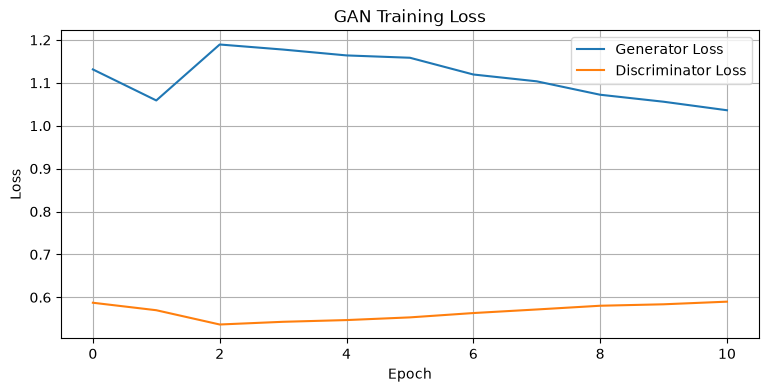

In [27]:
plt.figure(figsize=(9, 4))

plt.plot(g_losses, label="Generator Loss")
plt.plot(d_losses, label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid()
plt.show()

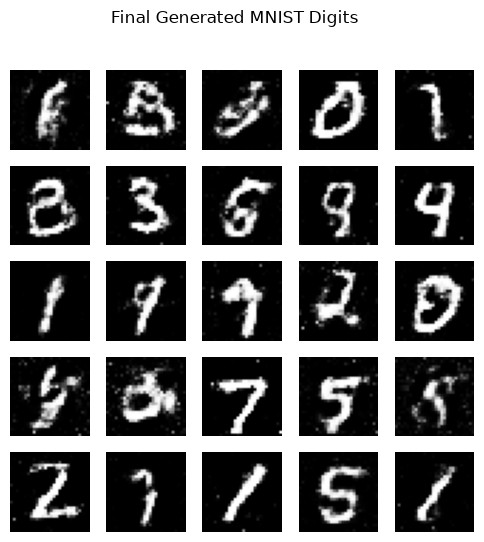

In [28]:
noise = tf.random.normal((25, latent_dim))
images = generator(noise, training=False)

plt.figure(figsize=(6, 6))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(images[i, :, :, 0], cmap="gray",
               vmin=-1, vmax=1)
    plt.axis("off")

plt.suptitle("Final Generated MNIST Digits")
plt.show()